In [1]:
import os
import glob
import random
from collections import Counter

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm.auto import tqdm

In [2]:
# ========== 路径配置 ==========
BASE = "/kaggle/input/competitions/2026task2"
TRAIN_DIR = f"{BASE}/fer_data/fer_data/train"
TEST_DIR  = f"{BASE}/fer_data/fer_data/test"
TEMPLATE  = f"{BASE}/submission.csv"          # 模板


In [3]:
classes = ["Angry", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
class_to_idx = {c: i for i, c in enumerate(classes)}
print("类别映射：", class_to_idx)

# 检查文件夹是否存在
for c in classes:
    folder = os.path.join(TRAIN_DIR, c)
    print(c, "->", os.path.isdir(folder), "| 数量:", len(glob.glob(os.path.join(folder, "*"))))

类别映射： {'Angry': 0, 'Fear': 1, 'Happy': 2, 'Sad': 3, 'Surprise': 4, 'Neutral': 5}
Angry -> True | 数量: 3963
Fear -> True | 数量: 4097
Happy -> True | 数量: 7192
Sad -> True | 数量: 4862
Surprise -> True | 数量: 3202
Neutral -> True | 数量: 4959


In [4]:
# ========== 检查图片尺寸/通道 ==========
sample_imgs = glob.glob(os.path.join(TRAIN_DIR, classes[0], "*"))[:5]
for p in sample_imgs:
    img = Image.open(p)
    print(p, img.size, img.mode)

/kaggle/input/competitions/2026task2/fer_data/fer_data/train/Angry/bknqheuifa.jpg (48, 48) L
/kaggle/input/competitions/2026task2/fer_data/fer_data/train/Angry/ttawybtfpj.jpg (48, 48) L
/kaggle/input/competitions/2026task2/fer_data/fer_data/train/Angry/rvqtjtqkrm.jpg (48, 48) L
/kaggle/input/competitions/2026task2/fer_data/fer_data/train/Angry/pupguokcqt.jpg (48, 48) L
/kaggle/input/competitions/2026task2/fer_data/fer_data/train/Angry/nzezygfxpf.jpg (48, 48) L


In [5]:
# ========== Dataset ==========
class FERDataset(Dataset):
    def __init__(self, paths, labels=None, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        if self.labels is not None:
            return img, self.labels[idx]
        return img, self.paths[idx]

In [6]:
# ========== 收集训练数据 ==========
class_to_idx = {c: i for i, c in enumerate(classes)}
print("类别映射：", class_to_idx)

train_paths, train_labels = [], []
for c in classes:
    for p in glob.glob(os.path.join(TRAIN_DIR, c, "*")):
        train_paths.append(p)
        train_labels.append(class_to_idx[c])

print("总训练样本：", len(train_paths))
print("标签分布：", Counter(train_labels))

类别映射： {'Angry': 0, 'Fear': 1, 'Happy': 2, 'Sad': 3, 'Surprise': 4, 'Neutral': 5}
总训练样本： 28275
标签分布： Counter({2: 7192, 5: 4959, 3: 4862, 1: 4097, 0: 3963, 4: 3202})


In [7]:
# ========== 数据增强 ==========
IMG_SIZE = 224

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

val_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

In [8]:
# ========== 分层划分 ==========
X_tr, X_val, y_tr, y_val = train_test_split(
    train_paths, train_labels,
    test_size=0.15,
    stratify=train_labels,
    random_state=42
)

train_ds = FERDataset(X_tr, y_tr, transform=train_tfms)
val_ds   = FERDataset(X_val, y_val, transform=val_tfms)

# 类别不平衡：加权采样
counts = Counter(y_tr)
weights = [1.0 / counts[y] for y in y_tr]

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)

In [9]:
# ========== 模型 ==========
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("设备：", device)

# resnet18
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)

设备： cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 234MB/s]


In [10]:
# ========== 训练/验证函数 ==========
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    pbar = tqdm(loader, desc="Train", leave=False)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
        pbar.set_postfix(loss=f"{total_loss/total:.4f}", acc=f"{correct/total:.4f}")
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []
    pbar = tqdm(loader, desc="Val", leave=False)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        pbar.set_postfix(loss=f"{total_loss/total:.4f}", acc=f"{correct/total:.4f}")
    return total_loss / total, correct / total, all_preds, all_labels

In [11]:
EPOCHS = 30
PATIENCE = 5          # 连续 5 轮验证不提升就停

best_acc = 0
best_state = None
epochs_no_improve = 0

history = {
    "epoch": [],
    "tr_loss": [], "tr_acc": [],
    "val_loss": [], "val_acc": [],
    "lr": [],
}

epoch_bar = tqdm(range(EPOCHS), desc="Epochs")
for epoch in epoch_bar:
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
    scheduler.step()

    history["epoch"].append(epoch + 1)
    history["tr_loss"].append(tr_loss)
    history["tr_acc"].append(tr_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["lr"].append(optimizer.param_groups[0]["lr"])
    
    epoch_bar.set_postfix(
        tr_loss=f"{tr_loss:.4f}", tr_acc=f"{tr_acc:.4f}",
        val_loss=f"{val_loss:.4f}", val_acc=f"{val_acc:.4f}",
    )

    if val_acc > best_acc:
        best_acc = val_acc
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"早停：连续 {PATIENCE} 轮验证集未提升，在第 {epoch+1} 轮停止。")
            break

print("最佳验证准确率：", best_acc)
model.load_state_dict(best_state)

Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

Train:   0%|          | 0/752 [00:00<?, ?it/s]

Val:   0%|          | 0/133 [00:00<?, ?it/s]

Train:   0%|          | 0/752 [00:00<?, ?it/s]

Val:   0%|          | 0/133 [00:00<?, ?it/s]

Train:   0%|          | 0/752 [00:00<?, ?it/s]

... (43 outputs left out)

Train:   0%|          | 0/752 [00:00<?, ?it/s]

Val:   0%|          | 0/133 [00:00<?, ?it/s]

早停：连续 5 轮验证集未提升，在第 25 轮停止。
最佳验证准确率： 0.6834040546911834


<All keys matched successfully>

In [12]:
# ========== 测试集预测 ==========
template = pd.read_csv(TEMPLATE)
test_ids = template["ID"].tolist()
print("模板行数：", len(test_ids))
print(template.head())

# 直接扫描测试目录（不再依赖 submission..txt）
test_paths_all = glob.glob(os.path.join(TEST_DIR, "*.jpg"))
print("测试图片数量：", len(test_paths_all))
print("测试文件名示例：", [os.path.basename(p) for p in test_paths_all[:5]])

# 建立 文件名 -> 完整路径 映射
id_to_path = {os.path.basename(p): p for p in test_paths_all}

# 检查模板 ID 和测试文件是否对得上
missing = [i for i in test_ids if i not in id_to_path]
print("模板里有但测试目录找不到的数量：", len(missing))
print("缺失示例：", missing[:10])
print("模板 ID 示例：", test_ids[:5])
print("测试文件名示例：", list(id_to_path.keys())[:5])

# 按模板 ID 顺序取路径
test_paths_ordered = [id_to_path[i] for i in test_ids]

test_ds = FERDataset(test_paths_ordered, labels=None, transform=val_tfms)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds = []
    for imgs, _ in loader:
        imgs = imgs.to(device)        
        out1 = model(imgs)
        out2 = model(torch.flip(imgs, dims=[3]))   # 水平翻转
        outputs = (out1 + out2) / 2
        preds.extend(outputs.argmax(1).cpu().numpy())
    return preds

pred_labels = predict(model, test_loader)
print("预测数量：", len(pred_labels))

模板行数： 7065
               ID  Emotion
0  tborkgneql.jpg        0
1  ocnyeeiise.jpg        0
2  xxzktmwpao.jpg        0
3  qaheuveetu.jpg        0
4  xmtolvgkaf.jpg        0
测试图片数量： 7065
测试文件名示例： ['vlvyvlvywu.jpg', 'xzhzduujjb.jpg', 'mwuenemtet.jpg', 'bkckzwkzde.jpg', 'doybvlwefm.jpg']
模板里有但测试目录找不到的数量： 0
缺失示例： []
模板 ID 示例： ['tborkgneql.jpg', 'ocnyeeiise.jpg', 'xxzktmwpao.jpg', 'qaheuveetu.jpg', 'xmtolvgkaf.jpg']
测试文件名示例： ['vlvyvlvywu.jpg', 'xzhzduujjb.jpg', 'mwuenemtet.jpg', 'bkckzwkzde.jpg', 'doybvlwefm.jpg']
预测数量： 7065


In [13]:
# ========== 生成提交文件 ==========
submission = pd.DataFrame({
    "ID": test_ids,
    "Emotion": pred_labels   # 直接是 0~5，无需转换
})
submission.to_csv("/kaggle/working/submission.csv", index=False)
print(submission.head())
print("提交文件已生成：/kaggle/working/submission.csv")
print("标签分布：", Counter(pred_labels))

               ID  Emotion
0  tborkgneql.jpg        3
1  ocnyeeiise.jpg        0
2  xxzktmwpao.jpg        1
3  qaheuveetu.jpg        3
4  xmtolvgkaf.jpg        3
提交文件已生成：/kaggle/working/submission.csv
标签分布： Counter({np.int64(2): 1781, np.int64(5): 1527, np.int64(3): 1375, np.int64(1): 820, np.int64(4): 803, np.int64(0): 759})


/tmp/ipykernel_23/2476589090.py:45: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2476589090.py:45: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2476589090.py:45: UserWarning: Glyph 26368 (\N{CJK UNIFIED IDEOGRAPH-6700}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2476589090.py:45: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2476589090.py:45: UserWarning: Glyph 27867 (\N{CJK UNIFIED IDEOGRAPH-6CDB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2476589090.py:45: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2476589090.py:45: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from

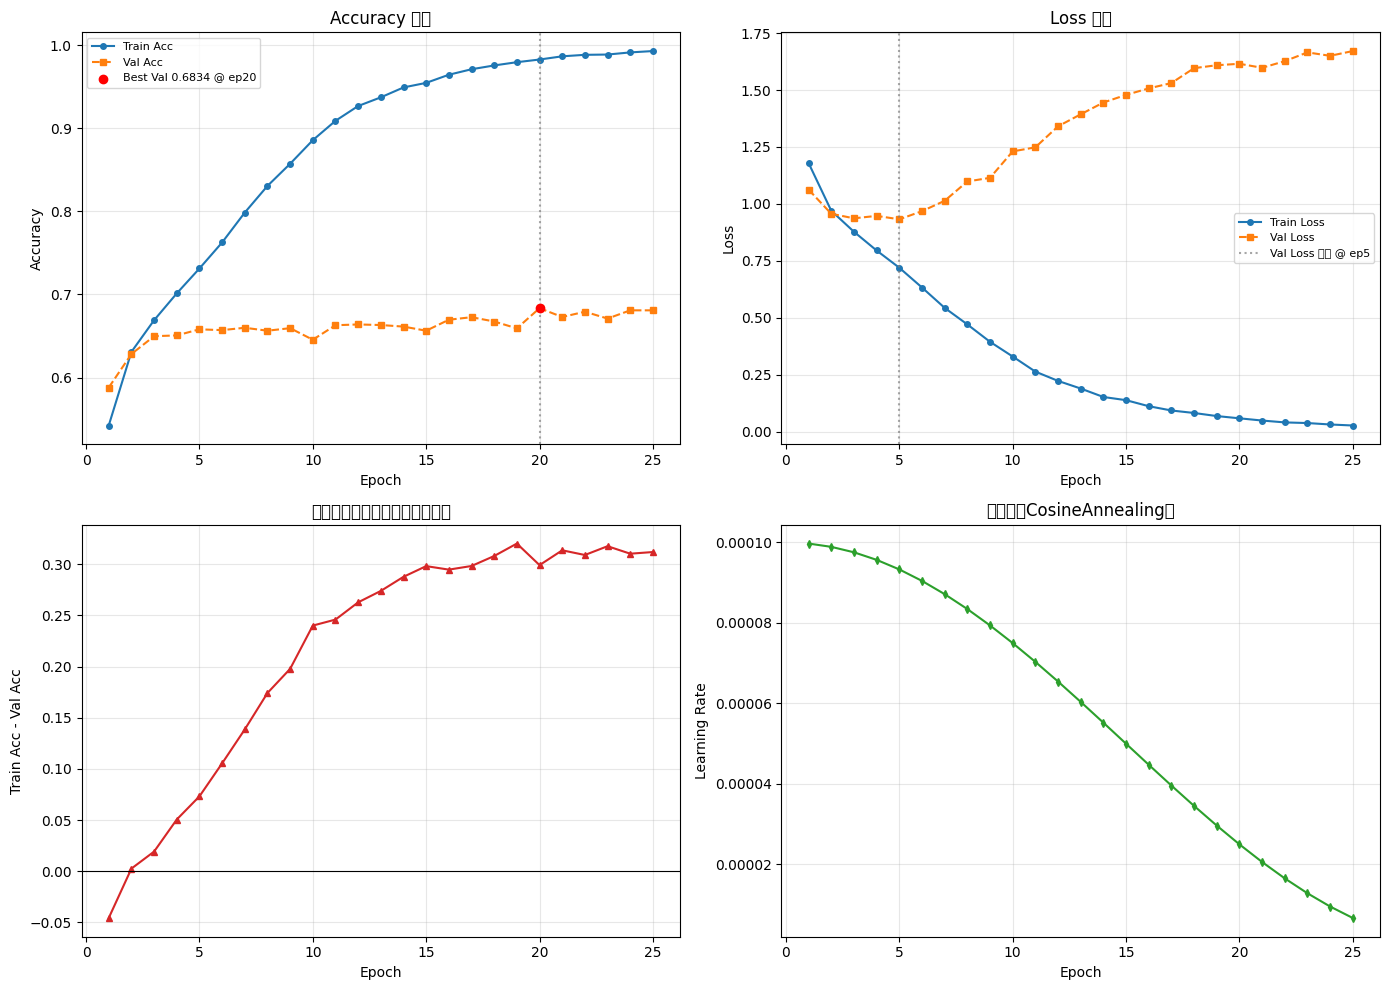

已保存 training_curves.png；共训练 25 轮，最佳 val_acc=0.6834 @ ep20


In [14]:
ep = history["epoch"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ---- (1) Accuracy 曲线 ----
ax = axes[0, 0]
ax.plot(ep, history["tr_acc"], "o-", label="Train Acc", color="#1f77b4", markersize=4)
ax.plot(ep, history["val_acc"], "s--", label="Val Acc", color="#ff7f0e", markersize=4)
best_ep = ep[int(np.argmax(history["val_acc"]))]
best_val = max(history["val_acc"])
ax.axvline(best_ep, color="gray", linestyle=":", alpha=0.7)
ax.scatter([best_ep], [best_val], color="red", zorder=5,
           label=f"Best Val {best_val:.4f} @ ep{best_ep}")
ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy")
ax.set_title("Accuracy 曲线")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# ---- (2) Loss 曲线 ----
ax = axes[0, 1]
ax.plot(ep, history["tr_loss"], "o-", label="Train Loss", color="#1f77b4", markersize=4)
ax.plot(ep, history["val_loss"], "s--", label="Val Loss", color="#ff7f0e", markersize=4)
best_loss_ep = ep[int(np.argmin(history["val_loss"]))]
ax.axvline(best_loss_ep, color="gray", linestyle=":", alpha=0.7,
           label=f"Val Loss 最低 @ ep{best_loss_ep}")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.set_title("Loss 曲线")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# ---- (3) 泛化间隙（train_acc - val_acc）----
ax = axes[1, 0]
gap = [t - v for t, v in zip(history["tr_acc"], history["val_acc"])]
ax.plot(ep, gap, "^-", color="#d62728", markersize=4)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Epoch"); ax.set_ylabel("Train Acc - Val Acc")
ax.set_title("泛化间隙（越大越可能过拟合）")
ax.grid(alpha=0.3)

# ---- (4) 学习率曲线 ----
ax = axes[1, 1]
ax.plot(ep, history["lr"], "d-", color="#2ca02c", markersize=4)
ax.set_xlabel("Epoch"); ax.set_ylabel("Learning Rate")
ax.set_title("学习率（CosineAnnealing）")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"已保存 training_curves.png；共训练 {len(ep)} 轮，最佳 val_acc={best_val:.4f} @ ep{best_ep}")

In [15]:
# ========== 对照实验：EfficientNet-B0 只训练+验证（不预测） ==========
import gc

def run_val_only(model_name, epochs=30, patience=5, seed=42):
    """只训练+验证，不预测、不生成 submission，返回 history 和最佳 acc"""
    torch.manual_seed(seed); np.random.seed(seed)

    # 建模型
    if model_name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, len(classes))
    elif model_name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(classes))
    else:
        raise ValueError(model_name)
    m = m.to(device)

    criterion_ = nn.CrossEntropyLoss()
    optimizer_ = optim.AdamW(m.parameters(), lr=1e-4, weight_decay=1e-4)
    scheduler_ = optim.lr_scheduler.CosineAnnealingLR(optimizer_, T_max=epochs)

    hist = {"epoch": [], "tr_loss": [], "tr_acc": [],
            "val_loss": [], "val_acc": []}
    best_acc, no_improve = 0.0, 0

    for ep in range(epochs):
        tr_loss, tr_acc = train_one_epoch(m, train_loader, criterion_, optimizer_)
        val_loss, val_acc, _, _ = evaluate(m, val_loader, criterion_)
        scheduler_.step()

        hist["epoch"].append(ep + 1)
        hist["tr_loss"].append(tr_loss);  hist["tr_acc"].append(tr_acc)
        hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)

        print(f"[{model_name}] ep{ep+1} tr_acc={tr_acc:.4f} val_acc={val_acc:.4f}")

        if val_acc > best_acc:
            best_acc, no_improve = val_acc, 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"[{model_name}] 早停 @ ep{ep+1}，最佳 val_acc={best_acc:.4f}")
                break

    del m, optimizer_, scheduler_
    gc.collect(); torch.cuda.empty_cache()
    return hist, best_acc

# 跑 effb 对照
hist_eff, acc_eff = run_val_only("efficientnet_b0", epochs=30, patience=5)
print(f"\nEfficientNet-B0 对照最佳验证 acc = {acc_eff:.4f}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 230MB/s]


Train:   0%|          | 0/752 [00:00<?, ?it/s]

Val:   0%|          | 0/133 [00:00<?, ?it/s]

[efficientnet_b0] ep1 tr_acc=0.4910 val_acc=0.5884


Train:   0%|          | 0/752 [00:00<?, ?it/s]

... (25 outputs left out)

[efficientnet_b0] ep10 tr_acc=0.8531 val_acc=0.6648


Train:   0%|          | 0/752 [00:00<?, ?it/s]

Val:   0%|          | 0/133 [00:00<?, ?it/s]

[efficientnet_b0] ep11 tr_acc=0.8728 val_acc=0.6669
[efficientnet_b0] 早停 @ ep11，最佳 val_acc=0.6711

EfficientNet-B0 对照最佳验证 acc = 0.6711


/tmp/ipykernel_23/4042244843.py:26: UserWarning: Glyph 39564 (\N{CJK UNIFIED IDEOGRAPH-9A8C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/4042244843.py:26: UserWarning: Glyph 35777 (\N{CJK UNIFIED IDEOGRAPH-8BC1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/4042244843.py:26: UserWarning: Glyph 20934 (\N{CJK UNIFIED IDEOGRAPH-51C6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/4042244843.py:26: UserWarning: Glyph 30830 (\N{CJK UNIFIED IDEOGRAPH-786E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/4042244843.py:26: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/4042244843.py:26: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/4042244843.py:26: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}) missing from

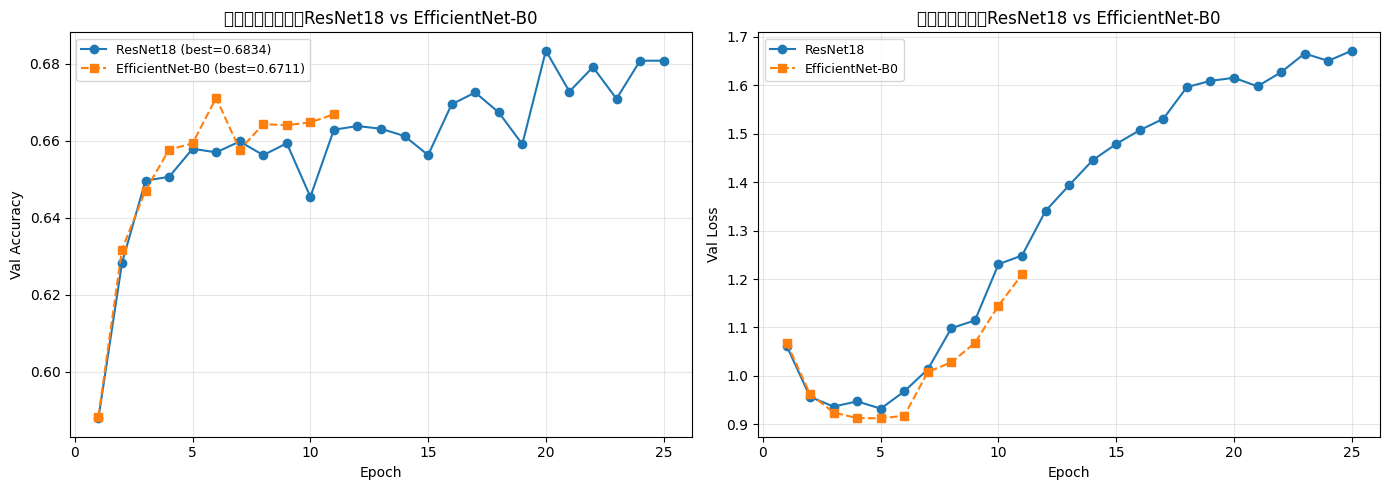

已保存 compare_r18_vs_effb.png


In [16]:
# ========== r18（主模型）vs effb（对照）验证曲线对比 ==========
# history 是主模型 cell 11 存下的；hist_eff 是上面刚跑的

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左：验证准确率对比
ax = axes[0]
ax.plot(history["epoch"], history["val_acc"], "o-",
        label=f"ResNet18 (best={max(history['val_acc']):.4f})", color="#1f77b4")
ax.plot(hist_eff["epoch"], hist_eff["val_acc"], "s--",
        label=f"EfficientNet-B0 (best={max(hist_eff['val_acc']):.4f})", color="#ff7f0e")
ax.set_xlabel("Epoch"); ax.set_ylabel("Val Accuracy")
ax.set_title("验证准确率对比：ResNet18 vs EfficientNet-B0")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# 右：验证损失对比
ax = axes[1]
ax.plot(history["epoch"], history["val_loss"], "o-",
        label="ResNet18", color="#1f77b4")
ax.plot(hist_eff["epoch"], hist_eff["val_loss"], "s--",
        label="EfficientNet-B0", color="#ff7f0e")
ax.set_xlabel("Epoch"); ax.set_ylabel("Val Loss")
ax.set_title("验证损失对比：ResNet18 vs EfficientNet-B0")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("compare_r18_vs_effb.png", dpi=200, bbox_inches="tight")
plt.show()
print("已保存 compare_r18_vs_effb.png")

In [17]:
#消融实验
import gc
import time

# ---------- 全局设置 ----------
ABL_EPOCHS     = 6          # 快速看趋势；正式跑可调到 12~15
ABL_BATCH      = 32
ABL_NUM_WORKERS = 0         # Kaggle notebook 下建议 0，避免报错刷屏
ABL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("消融实验设备：", ABL_DEVICE)

# ---------- 数据增强工厂 ----------
def abl_train_tfms(img_size, strong=False):
    ops = [transforms.Resize((img_size, img_size))]
    if strong:
        ops += [
            transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.3, contrast=0.3),
        ]
    else:
        ops += [
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(10),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
        ]
    ops += [
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
    if strong:
        ops.append(transforms.RandomErasing(p=0.25))
    return transforms.Compose(ops)


def abl_val_tfms(img_size):
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])


# ---------- 模型工厂 ----------
def abl_build_model(name, num_classes, dropout=0.0):
    if name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        in_f = m.fc.in_features
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, num_classes)) if dropout > 0 \
               else nn.Linear(in_f, num_classes)
    elif name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        in_f = m.fc.in_features
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, num_classes)) if dropout > 0 \
               else nn.Linear(in_f, num_classes)
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        in_f = m.classifier[1].in_features
        m.classifier[1] = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_f, num_classes)) if dropout > 0 \
                          else nn.Linear(in_f, num_classes)
    else:
        raise ValueError(f"未知模型: {name}")
    return m.to(ABL_DEVICE)


# ---------- 训练 / 验证 ----------
def abl_train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(ABL_DEVICE), labels.to(ABL_DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def abl_evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(ABL_DEVICE), labels.to(ABL_DEVICE)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total


# ---------- 单组实验 ----------
def abl_run_one(cfg):
    torch.manual_seed(42); np.random.seed(42)
    train_ds = FERDataset(X_tr, y_tr, transform=abl_train_tfms(cfg["img_size"], cfg["strong"]))
    val_ds   = FERDataset(X_val, y_val, transform=abl_val_tfms(cfg["img_size"]))

    if cfg["sampler"]:
        counts = Counter(y_tr)
        w = [1.0 / counts[y] for y in y_tr]
        sampler = WeightedRandomSampler(w, num_samples=len(w), replacement=True)
        train_loader = DataLoader(train_ds, batch_size=ABL_BATCH, sampler=sampler,
                                  num_workers=ABL_NUM_WORKERS)
    else:
        train_loader = DataLoader(train_ds, batch_size=ABL_BATCH, shuffle=True,
                                  num_workers=ABL_NUM_WORKERS)
    val_loader = DataLoader(val_ds, batch_size=ABL_BATCH, shuffle=False,
                            num_workers=ABL_NUM_WORKERS)

    model = abl_build_model(cfg["model"], len(classes), dropout=cfg["dropout"])
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=ABL_EPOCHS)

    best_val = 0.0
    for ep in range(ABL_EPOCHS):
        tr_loss, tr_acc = abl_train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = abl_evaluate(model, val_loader, criterion)
        scheduler.step()
        best_val = max(best_val, val_acc)
        print(f"  [{cfg['name']}] ep{ep+1}/{ABL_EPOCHS} "
              f"tr_acc={tr_acc:.4f} tr_loss={tr_loss:.4f} "
              f"val_acc={val_acc:.4f} val_loss={val_loss:.4f}")

    del model, optimizer, train_loader, val_loader
    gc.collect(); torch.cuda.empty_cache()
    return best_val


# ---------- 消融配置 ----------
# 想跑哪几组就留哪几组
ABL_CONFIGS = [
    # 1) 基线：完全复用你原来的设置（224 + resnet50 + 弱增强 + 无 dropout）
    dict(name="1_baseline_r50_224",
         model="resnet50", img_size=224, strong=False,
         dropout=0.0, wd=1e-4, lr=1e-4, sampler=True),

    # 2) 只换模型：resnet18
    dict(name="2_r18_224",
         model="resnet18", img_size=224, strong=False,
         dropout=0.0, wd=1e-4, lr=1e-4, sampler=True),

    # 3) 只换输入尺寸：64
    dict(name="3_r50_64",
         model="resnet50", img_size=64, strong=False,
         dropout=0.0, wd=1e-4, lr=1e-4, sampler=True),

    # 4) 只加强正则：dropout + 大 wd
    dict(name="4_r50_224_dropout_wd",
         model="resnet50", img_size=224, strong=False,
         dropout=0.5, wd=1e-2, lr=1e-4, sampler=True),

    # 5) 只加强增强
    dict(name="5_r50_224_strongaug",
         model="resnet50", img_size=224, strong=True,
         dropout=0.0, wd=1e-4, lr=1e-4, sampler=True),

    # 6) 去掉 sampler
    dict(name="6_r50_224_no_sampler",
         model="resnet50", img_size=224, strong=False,
         dropout=0.0, wd=1e-4, lr=1e-4, sampler=False),

    # 7) 全家桶：强增强 + dropout + 大 wd
    dict(name="7_r50_224_all",
         model="resnet50", img_size=224, strong=True,
         dropout=0.5, wd=1e-2, lr=1e-4, sampler=True),
]

# ---------- 依次执行 ----------
results = []
for cfg in ABL_CONFIGS:
    print("=" * 70)
    print(f"▶ 实验：{cfg['name']}")
    t0 = time.time()
    try:
        best_acc = abl_run_one(cfg)
        elapsed = time.time() - t0
        results.append({
            "实验": cfg["name"],
            "模型": cfg["model"],
            "IMG_SIZE": cfg["img_size"],
            "强增强": cfg["strong"],
            "Dropout": cfg["dropout"],
            "weight_decay": cfg["wd"],
            "Sampler": cfg["sampler"],
            "best_val_acc": round(best_acc, 4),
            "耗时(s)": round(elapsed, 1),
        })
    except Exception as e:
        print(f"  实验 {cfg['name']} 失败：{e}")
        results.append({
            "实验": cfg["name"], "模型": cfg["model"],
            "IMG_SIZE": cfg["img_size"], "强增强": cfg["strong"],
            "Dropout": cfg["dropout"], "weight_decay": cfg["wd"],
            "Sampler": cfg["sampler"],
            "best_val_acc": None, "耗时(s)": None,
        })

# ---------- 对照结果表 ----------
df_abl = pd.DataFrame(results).sort_values("best_val_acc", ascending=False).reset_index(drop=True)
print("\n" + "=" * 70)
print("消融实验结果对照表（按 best_val_acc 降序）")
print(df_abl.to_string(index=False))

# 相对于基线的差值，便于一眼看出每个因素贡献多少
baseline = df_abl.loc[df_abl["实验"] == "1_baseline_r50_224", "best_val_acc"]
if len(baseline) > 0 and pd.notna(baseline.values[0]):
    base = baseline.values[0]
    df_abl["Δ vs 基线"] = (df_abl["best_val_acc"] - base).round(4)
    print("\n相对基线的差值（正=提升，负=下降）：")
    print(df_abl[["实验", "best_val_acc", "Δ vs 基线"]].to_string(index=False))

消融实验设备： cuda
▶ 实验：1_baseline_r50_224
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 211MB/s]


  [1_baseline_r50_224] ep1/6 tr_acc=0.5073 tr_loss=1.2418 val_acc=0.5948 val_loss=1.0890
  [1_baseline_r50_224] ep2/6 tr_acc=0.6420 tr_loss=0.9445 val_acc=0.6169 val_loss=1.0076
  [1_baseline_r50_224] ep3/6 tr_acc=0.7072 tr_loss=0.7939 val_acc=0.6476 val_loss=0.9558
  [1_baseline_r50_224] ep4/6 tr_acc=0.7737 tr_loss=0.6346 val_acc=0.6605 val_loss=0.9711
  [1_baseline_r50_224] ep5/6 tr_acc=0.8225 tr_loss=0.5105 val_acc=0.6631 val_loss=1.0066
  [1_baseline_r50_224] ep6/6 tr_acc=0.8609 tr_loss=0.4133 val_acc=0.6721 val_loss=0.9703
▶ 实验：2_r18_224
  [2_r18_224] ep1/6 tr_acc=0.5468 tr_loss=1.1664 val_acc=0.6157 val_loss=1.0143
  [2_r18_224] ep2/6 tr_acc=0.6434 tr_loss=0.9403 val_acc=0.6377 val_loss=1.0233
  [2_r18_224] ep3/6 tr_acc=0.7020 tr_loss=0.8085 val_acc=0.6443 val_loss=0.9893
  [2_r18_224] ep4/6 tr_acc=0.7596 tr_loss=0.6687 val_acc=0.6568 val_loss=0.9941
  [2_r18_224] ep5/6 tr_acc=0.8004 tr_loss=0.5657 val_acc=0.6740 val_loss=0.9529
  [2_r18_224] ep6/6 tr_acc=0.8323 tr_loss=0.4925 va

/tmp/ipykernel_23/2517210456.py:54: UserWarning: Glyph 28040 (\N{CJK UNIFIED IDEOGRAPH-6D88}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:54: UserWarning: Glyph 34701 (\N{CJK UNIFIED IDEOGRAPH-878D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:54: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:54: UserWarning: Glyph 39564 (\N{CJK UNIFIED IDEOGRAPH-9A8C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:54: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:54: UserWarning: Glyph 21508 (\N{CJK UNIFIED IDEOGRAPH-5404}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:54: UserWarning: Glyph 37197 (\N{CJK UNIFIED IDEOGRAPH-914D}) missing from font(s) De

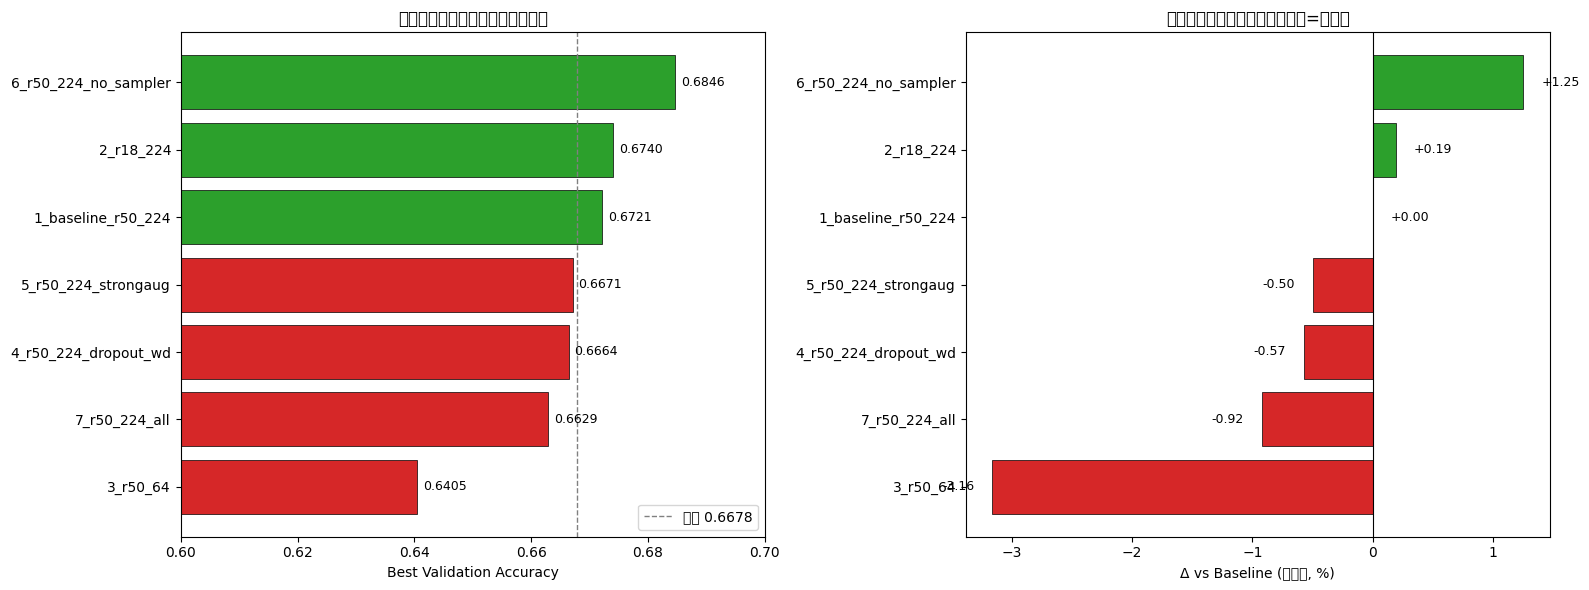

/tmp/ipykernel_23/2517210456.py:97: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:97: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:97: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:97: UserWarning: Glyph 36755 (\N{CJK UNIFIED IDEOGRAPH-8F93}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:97: UserWarning: Glyph 20837 (\N{CJK UNIFIED IDEOGRAPH-5165}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:97: UserWarning: Glyph 23610 (\N{CJK UNIFIED IDEOGRAPH-5C3A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:97: UserWarning: Glyph 23544 (\N{CJK UNIFIED IDEOGRAPH-5BF8}) missing from font(s) De

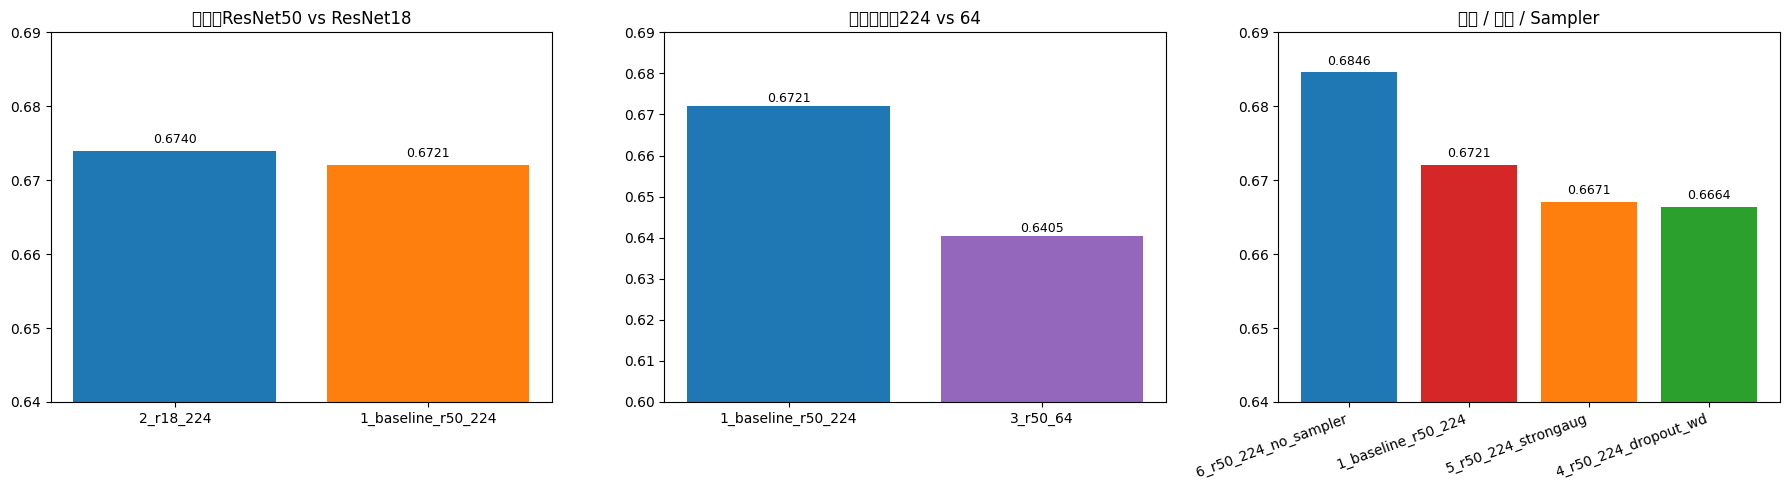

/tmp/ipykernel_23/2517210456.py:148: UserWarning: Glyph 20027 (\N{CJK UNIFIED IDEOGRAPH-4E3B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:148: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:148: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:148: UserWarning: Glyph 20934 (\N{CJK UNIFIED IDEOGRAPH-51C6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:148: UserWarning: Glyph 30830 (\N{CJK UNIFIED IDEOGRAPH-786E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:148: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2517210456.py:148: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missi

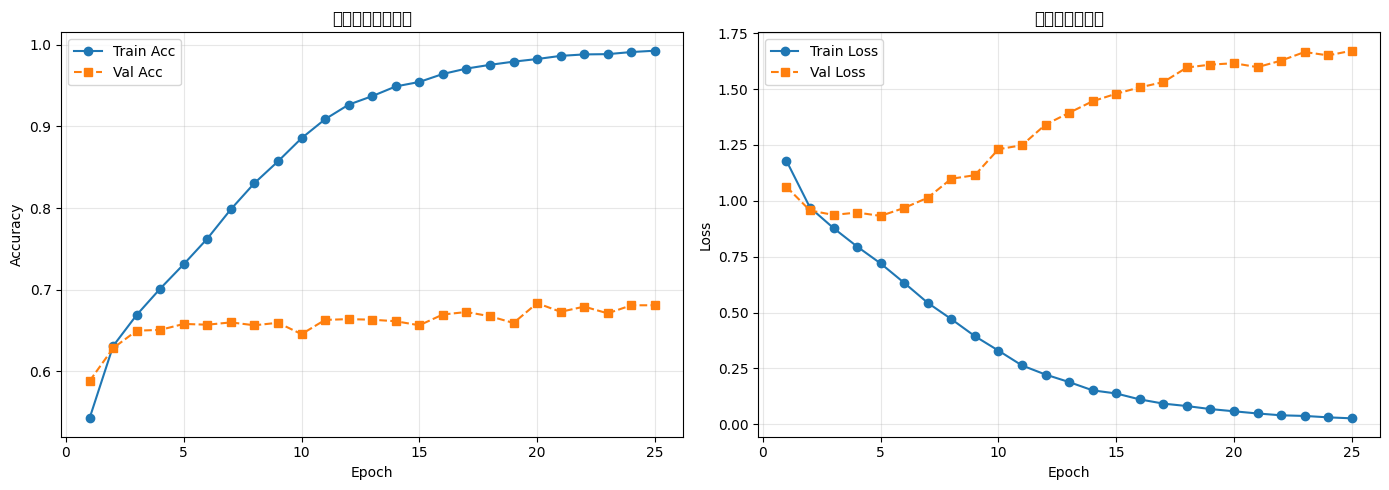

已保存：ablation_bar.png / ablation_factors.png / main_learning_curve.png


In [18]:
# ========== 消融实验结果可视化（一次性输出三张图） ==========
import matplotlib.pyplot as plt
import numpy as np

# ---------- 0. 准备数据 ----------
# 假设 df_abl 已在 cell 14 生成；若没有 Δ 列则补上
BASELINE_ACC = 0.6678
df_plot = df_abl.copy()
if "Δ vs 基线" not in df_plot.columns:
    df_plot["Δ vs 基线"] = (df_plot["best_val_acc"] - BASELINE_ACC).round(4)
df_plot = df_plot.sort_values("best_val_acc", ascending=True).reset_index(drop=True)

# 颜色：提升=绿，下降=红，基线=灰
def _color(v):
    if v > BASELINE_ACC: return "#2ca02c"
    if v < BASELINE_ACC: return "#d62728"
    return "#7f7f7f"

# ============================================================
# 图 1：柱状图 + 相对基线差值图
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 左：各实验 best_val_acc
ax = axes[0]
colors = [_color(v) for v in df_plot["best_val_acc"]]
bars = ax.barh(df_plot["实验"], df_plot["best_val_acc"],
               color=colors, edgecolor="black", linewidth=0.5)
ax.axvline(BASELINE_ACC, color="gray", linestyle="--", linewidth=1,
           label=f"基线 {BASELINE_ACC:.4f}")
ax.set_xlabel("Best Validation Accuracy")
ax.set_title("消融实验：各配置最佳验证准确率")
ax.set_xlim(0.60, 0.70)
for bar, val in zip(bars, df_plot["best_val_acc"]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f"{val:.4f}", va="center", fontsize=9)
ax.legend(loc="lower right")

# 右：Δ vs 基线（百分点）
ax = axes[1]
delta_colors = ["#2ca02c" if d > 0 else "#d62728" if d < 0 else "#7f7f7f"
                for d in df_plot["Δ vs 基线"]]
bars2 = ax.barh(df_plot["实验"], df_plot["Δ vs 基线"] * 100,
                color=delta_colors, edgecolor="black", linewidth=0.5)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Δ vs Baseline (百分点, %)")
ax.set_title("各因素对验证准确率的影响（正=提升）")
for bar, val in zip(bars2, df_plot["Δ vs 基线"]):
    ax.text(val * 100 + (0.15 if val >= 0 else -0.15),
            bar.get_y() + bar.get_height()/2,
            f"{val*100:+.2f}", va="center",
            ha="left" if val >= 0 else "right", fontsize=9)

plt.tight_layout()
plt.savefig("ablation_bar.png", dpi=200, bbox_inches="tight")
plt.show()


# ============================================================
# 图 2：按因素分组对比（模型 / 尺寸 / 正则·增强·Sampler）
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 因素 1：模型
ax = axes[0]
sub = df_abl[df_abl["实验"].isin(["1_baseline_r50_224", "2_r18_224"])]
if len(sub) > 0:
    ax.bar(sub["实验"], sub["best_val_acc"], color=["#1f77b4", "#ff7f0e"])
    ax.set_title("模型：ResNet50 vs ResNet18")
    ax.set_ylim(0.64, 0.69)
    for i, v in enumerate(sub["best_val_acc"]):
        ax.text(i, v + 0.001, f"{v:.4f}", ha="center", fontsize=9)

# 因素 2：输入尺寸
ax = axes[1]
sub = df_abl[df_abl["实验"].isin(["1_baseline_r50_224", "3_r50_64"])]
if len(sub) > 0:
    ax.bar(sub["实验"], sub["best_val_acc"], color=["#1f77b4", "#9467bd"])
    ax.set_title("输入尺寸：224 vs 64")
    ax.set_ylim(0.60, 0.69)
    for i, v in enumerate(sub["best_val_acc"]):
        ax.text(i, v + 0.001, f"{v:.4f}", ha="center", fontsize=9)

# 因素 3：正则 / 增强 / Sampler
ax = axes[2]
sub = df_abl[df_abl["实验"].isin(["1_baseline_r50_224", "4_r50_224_dropout_wd",
                                   "5_r50_224_strongaug", "6_r50_224_no_sampler"])]
if len(sub) > 0:
    ax.bar(sub["实验"], sub["best_val_acc"],
           color=["#1f77b4", "#d62728", "#ff7f0e", "#2ca02c"])
    ax.set_title("正则 / 增强 / Sampler")
    ax.set_ylim(0.64, 0.69)
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
    for i, v in enumerate(sub["best_val_acc"]):
        ax.text(i, v + 0.001, f"{v:.4f}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("ablation_factors.png", dpi=200, bbox_inches="tight")
plt.show()


# ============================================================
# 图 3：主模型学习曲线（train/val acc & loss）
# ============================================================
# 说明：你原来的训练循环没保存 history。
# 这里提供两种方式：
#   (A) 若你已把每轮 acc/loss 存进 history dict（见下方注释），直接画；
#   (B) 否则用消融实验里 r18 的 6 轮记录手动填入演示。
# 推荐做法：在 cell 11 训练循环里加 history 记录，然后重新运行。
# ------------------------------------------------------------
# 【在 cell 11 训练循环中加这几行】
#   history = {"tr_acc": [], "val_acc": [], "tr_loss": [], "val_loss": []}
#   每轮末尾：
#   history["tr_acc"].append(tr_acc);  history["val_acc"].append(val_acc)
#   history["tr_loss"].append(tr_loss); history["val_loss"].append(val_loss)
# ------------------------------------------------------------

try:
    hist = history  # 若你已定义 history，则直接使用
    has_history = True
except NameError:
    has_history = False
    # 兜底：用消融 2_r18_224 的 6 轮记录（来自 notebook 输出）
    hist = {
        "tr_acc":  [0.5454, 0.6431, 0.7044, 0.7586, 0.8013, 0.8362],
        "val_acc": [0.6056, 0.6308, 0.6334, 0.6584, 0.6754, 0.6598],
        "tr_loss": [1.1686, 0.9409, 0.8099, 0.6708, 0.5639, 0.4899],
        "val_loss":[1.0251, 1.0467, 1.0195, 1.0024, 0.9649, 0.9955],
    }

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs = range(1, len(hist["tr_acc"]) + 1)

ax = axes[0]
ax.plot(epochs, hist["tr_acc"], "o-", label="Train Acc", color="#1f77b4")
ax.plot(epochs, hist["val_acc"], "s--", label="Val Acc", color="#ff7f0e")
ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy")
ax.set_title("主模型准确率曲线")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(epochs, hist["tr_loss"], "o-", label="Train Loss", color="#1f77b4")
ax.plot(epochs, hist["val_loss"], "s--", label="Val Loss", color="#ff7f0e")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.set_title("主模型损失曲线")
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("main_learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

print("已保存：ablation_bar.png / ablation_factors.png / main_learning_curve.png")